# US Wildfire EDA

Fires: Table including wildfire data for the period of 1992-2015 compiled from US federal, state, and local reporting systems.
* FOD_ID = Global unique identifier.
* FPA_ID = Unique identifier that contains information necessary to track back to the original record in the source dataset.
* SOURCE_SYSTEM_TYPE = Type of source database or system that the record was drawn from (federal, nonfederal, or interagency).
* SOURCE_SYSTEM = Name of or other identifier for source database or system that the record was drawn from.
* NWCG_REPORTING_AGENCY = Active National Wildlife Coordinating Group (NWCG) Unit Identifier for the agency preparing the fire report.
* NWCG_REPORTING_UNIT_ID = Active NWCG Unit Identifier for the unit preparing the fire report.
* NWCG_REPORTING_UNIT_NAME = Active NWCG Unit Name for the unit preparing the fire report.
* SOURCE_REPORTING_UNIT = Code for the agency unit preparing the fire report, based on code/name in the source dataset.
* SOURCE_REPORTING_UNIT_NAME = Name of reporting agency unit preparing the fire report, based on code/name in the source dataset.
* LOCAL_FIRE_REPORT_ID = Number or code that uniquely identifies an incident report for a particular reporting unit and a particular calendar year.
* LOCAL_INCIDENT_ID = Number or code that uniquely identifies an incident for a particular local fire management organization within a particular calendar year.
* FIRE_CODE = Code used within the interagency wildland fire community to track and compile cost information for emergency fire suppression.
* FIRE_NAME = Name of the incident.
* ICS_209_INCIDENT_NUMBER = Incident (event) identifier, from the ICS-209 report.
* ICS_209_NAME = Name of the incident, from the ICS-209 report.
* MTBS_ID = Incident identifier, from the MTBS perimeter dataset.
* MTBS_FIRE_NAME = Name of the incident, from the MTBS perimeter dataset.
* COMPLEX_NAME = Name of the complex under which the fire was ultimately managed, when discernible.
* **FIRE_YEAR** = Calendar year in which the fire was discovered or confirmed to exist.
* **DISCOVERY_DATE** = Date on which the fire was discovered or confirmed to exist.
* **DISCOVERY_DOY** = Day of year on which the fire was discovered or confirmed to exist.
* **DISCOVERY_TIME** = Time of day that the fire was discovered or confirmed to exist.
* **STAT_CAUSE_CODE** = Code for the (statistical) cause of the fire.
* **STAT_CAUSE_DESCR** = Description of the (statistical) cause of the fire.
* **CONT_DATE** = Date on which the fire was declared contained or otherwise controlled (mm/dd/yyyy where mm=month, dd=day, and yyyy=year).
* **CONT_DOY** = Day of year on which the fire was declared contained or otherwise controlled.
* **CONT_TIME** = Time of day that the fire was declared contained or otherwise controlled (hhmm where hh=hour, mm=minutes).
* **FIRE_SIZE** = Estimate of acres within the final perimeter of the fire.
* **FIRE_SIZE_CLASS** = Code for fire size based on the number of acres within the final fire perimeter expenditures (A=greater than 0 but less than or equal to 0.25 acres, B=0.26-9.9 acres, C=10.0-99.9 acres, D=100-299 acres, E=300 to 999 acres, F=1000 to 4999 acres, and G=5000+ acres).
* **LATITUDE** = Latitude (NAD83) for point location of the fire (decimal degrees).
* **LONGITUDE** = Longitude (NAD83) for point location of the fire (decimal degrees).
* **OWNER_CODE** = Code for primary owner or entity responsible for managing the land at the point of origin of the fire at the time of the incident.
* **OWNER_DESCR** = Name of primary owner or entity responsible for managing the land at the point of origin of the fire at the time of the incident.
* **STATE** = Two-letter alphabetic code for the state in which the fire burned (or originated), based on the nominal designation in the fire report.
* **COUNTY** = County, or equivalent, in which the fire burned (or originated), based on nominal designation in the fire report.
* FIPS_CODE = Three-digit code from the Federal Information Process Standards (FIPS) publication 6-4 for representation of counties and equivalent entities.
* FIPS_NAME = County name from the FIPS publication 6-4 for representation of





## imports

In [ ]:
!pip install pygeohash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 3.5 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint
%matplotlib inline
import matplotlib
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import pygeohash as pgh
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier, GradientBoostingClassifier
import lightgbm as lgb
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib
import warnings
import os


from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer


warnings.filterwarnings('ignore')

warnings.filterwarnings('ignore')
plt.style.use('ggplot')

## Load data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PRE_PATH = "/content/drive/My Drive/Code/Wildfire DRW/"

Mounted at /content/drive


In [ ]:
import kagglehub


path = kagglehub.dataset_download("rtatman/188-million-us-wildfires")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/188-million-us-wildfires


In [ ]:
import sqlite3
conn = sqlite3.connect(os.path.join(path, 'FPA_FOD_20170508.sqlite'))
columns = ["FIRE_YEAR",
           "DISCOVERY_DATE",
           "DISCOVERY_DOY",
           "DISCOVERY_TIME",
           "STAT_CAUSE_CODE",
           "STAT_CAUSE_DESCR",
           "CONT_DATE",
           "CONT_DOY",
           "FIRE_SIZE",
           "FIRE_SIZE_CLASS",
           "LATITUDE",
           "LONGITUDE",
           "OWNER_DESCR",
           "STATE",
           'NWCG_REPORTING_UNIT_ID', 'NWCG_REPORTING_AGENCY', 'SOURCE_SYSTEM_TYPE', 'SOURCE_SYSTEM']

df_orig = pd.read_sql_query(f"SELECT {','.join(columns)} FROM Fires", conn)

In [ ]:
df = df_orig
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1880465 entries, 0 to 1880464
Data columns (total 18 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   FIRE_YEAR               int64  
 1   DISCOVERY_DATE          float64
 2   DISCOVERY_DOY           int64  
 3   DISCOVERY_TIME          object 
 4   STAT_CAUSE_CODE         float64
 5   STAT_CAUSE_DESCR        object 
 6   CONT_DATE               float64
 7   CONT_DOY                float64
 8   FIRE_SIZE               float64
 9   FIRE_SIZE_CLASS         object 
 10  LATITUDE                float64
 11  LONGITUDE               float64
 12  OWNER_DESCR             object 
 13  STATE                   object 
 14  NWCG_REPORTING_UNIT_ID  object 
 15  NWCG_REPORTING_AGENCY   object 
 16  SOURCE_SYSTEM_TYPE      object 
 17  SOURCE_SYSTEM           object 
dtypes: float64(7), int64(2), object(9)
memory usage: 258.2+ MB


## Prepare data

In [ ]:
def prepare_date_data(df):
    df['DISCOVERY_TIME'] = pd.to_datetime(df['DISCOVERY_TIME'], format='%H%M', errors='coerce').dt.time

    df['DISCOVERY_DATE'] = pd.to_datetime(df['DISCOVERY_DATE'], unit='D', origin='julian')
    df['CONT_DATE'] = pd.to_datetime(df['CONT_DATE'], unit='D', origin='julian')
    df['STR_FIRE_YEAR'] = df['FIRE_YEAR'].astype(str)
    df['month'] = df['DISCOVERY_DATE'].dt.month
    df['STR_DISCOVERY_DOY'] = df['DISCOVERY_DOY'].astype(str)
    df['DISCOVERY_DOY_INV'] = 366 - df['DISCOVERY_DOY']
    df["STR_DISCOVERY_DOY_INV"] = ((366 - df["DISCOVERY_DOY"]) // 20).astype(str)
    df["STR_STAT_CAUSE_CODE"] = df["STAT_CAUSE_CODE"].astype(str)
    df['FIRE_SIZE'] = df['FIRE_SIZE'].astype(float)
    df['log_fire_size'] = np.log1p(df['FIRE_SIZE'])
    df['DICOVERY_MONTH'] = df['DISCOVERY_DATE'].dt.month
    df['DAY_OF_WEEK'] = df['DISCOVERY_DATE'].dt.dayofweek
    def month_to_season(m):
        if pd.isna(m): return np.nan
        if m in [12,1,2]: return 'winter'
        if m in [3,4,5]: return 'spring'
        if m in [6,7,8]: return 'summer'
        return 'autumn'
    df['season'] = df['month'].apply(month_to_season)
    df['DURATION_DAY'] = (df['CONT_DATE'] - df['DISCOVERY_DATE']).dt.days
    def create_cyclic_features(df, col, max_val):
      df[f'{col}_sin'] = np.sin(2 * np.pi * df[col] / max_val)
      df[f'{col}_cos'] = np.cos(2 * np.pi * df[col] / max_val)
      return df
    df = create_cyclic_features(df, 'DICOVERY_MONTH', 12)
    df = create_cyclic_features(df, 'DISCOVERY_DOY', 365)





    return df
def prepare_location_data(df, geohash_precision=2):
    df['GEOHASH'] = df.apply(lambda row: pgh.encode(row['LATITUDE'], row['LONGITUDE'], precision=geohash_precision),axis=1)
    return df

In [ ]:
df = prepare_date_data(df)
df = prepare_location_data(df)

## Fire Size Prediction

In [ ]:

def prepare_data_for_fire_size(df, columns, apply_log=None):
    df = df[
        (df["FIRE_SIZE"].notnull()) &
        (df["FIRE_SIZE"] > 0) &
        (df["DURATION_DAY"] > 0)
    ].copy()


    if apply_log is not None:
      for column_name in apply_log:
        df[column_name] = df[column_name].apply(np.log)
      X = df[columns]
      y = df["FIRE_SIZE"].apply(np.log)
    else:
      X = df[columns]
      y = df["FIRE_SIZE"]

    X_numerical = X.select_dtypes(include=["float", "int"])
    fill_nan = lambda col: col.fillna(col.mean())
    X_numerical = X_numerical.apply(fill_nan)

    X_categorical = X.select_dtypes(include=["object"])
    X_categorical = pd.get_dummies(X_categorical, dummy_na=False, drop_first=True)


    X = pd.concat([X_numerical, X_categorical], axis=1)

    return X, y



In [ ]:
def fit_model(X, y, model, name="model"):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.02, random_state=42)
    lm_model = model

    if os.path.exists(f"{PRE_PATH}models/{name}_lm_model.joblib"):
        print("Loading", name)
        lm_model = joblib.load(f"{PRE_PATH}models/{name}_lm_model.joblib")
    else:
        print("Training", name)
        lm_model.fit(X_train, y_train)
        joblib.dump(lm_model, f"{PRE_PATH}models/{name}_lm_model.joblib")


    y_test_preds = lm_model.predict(X_test)
    y_train_preds = lm_model.predict(X_train)



    test_score = r2_score(y_test, y_test_preds)
    train_score = r2_score(y_train, y_train_preds)

    return dict(test_score=test_score, train_score=train_score)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
columns = [
    "DURATION_DAY",

    "GEOHASH",
    "LATITUDE",
    "LONGITUDE",

    "STR_FIRE_YEAR",
    "DISCOVERY_DOY",


    "DICOVERY_MONTH_sin",
    "DICOVERY_MONTH_cos",
    "DISCOVERY_DOY_sin",
    "DISCOVERY_DOY_cos",
    "DAY_OF_WEEK",



    "STAT_CAUSE_DESCR",







    "season"
]


X_log, y_log = prepare_data_for_fire_size(
    df,
    columns,
    apply_log=["DURATION_DAY"]
)
linear_regression_with_log = fit_model(X_log, y_log,  LinearRegression(fit_intercept=True),"linear_regression_with_log")
random_forest_with_log = fit_model(X_log, y_log, RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),"random_forest_with_log")

Training linear_regression_with_log
Training random_forest_with_log


Training linear_regression_without_log
Training random_forest_without_log


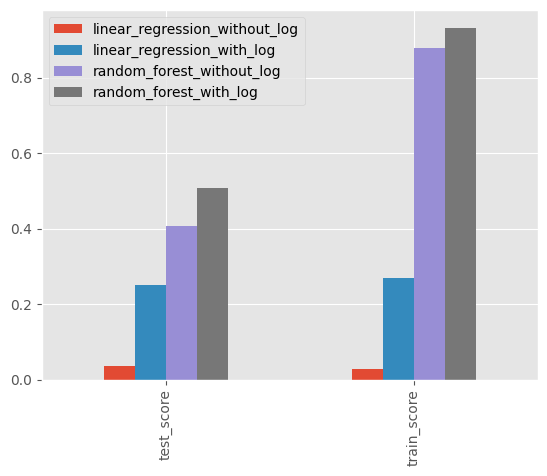

In [ ]:

X, y = prepare_data_for_fire_size(
    df,
    columns
)
linear_regression_without_log = fit_model(X, y,  LinearRegression(fit_intercept=True),"linear_regression_without_log")
random_forest_without_log = fit_model(X, y, RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),"random_forest_without_log")

plot = pd.DataFrame.from_records([linear_regression_without_log, linear_regression_with_log, random_forest_without_log, random_forest_with_log], index=["linear_regression_without_log", "linear_regression_with_log", "random_forest_without_log", "random_forest_with_log"]).T.plot.bar();

plot.figure.savefig(f"{PRE_PATH}plots/scores_with_season.png")
plt.show()

In [ ]:
print(linear_regression_without_log)
print(linear_regression_with_log)
print(random_forest_without_log)
print(random_forest_with_log)

{'test_score': 0.03493074350255332, 'train_score': 0.02708110295835675}
{'test_score': 0.24938587206505203, 'train_score': 0.2682666818345205}
{'test_score': 0.40780047705931166, 'train_score': 0.8792649341216627}
{'test_score': 0.508232591386879, 'train_score': 0.9335554224563324}


## Cause prediction

In [ ]:


y = df['STAT_CAUSE_DESCR']
X = df.drop('STAT_CAUSE_DESCR', axis=1)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Data split into training and testing sets.")


geo_temporal_features = ['GEOHASH', 'STATE', 'season', 'DISCOVERY_DOY', 'STR_FIRE_YEAR','LATITUDE','LONGITUDE']
geo_temporal_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())]),
         ['DISCOVERY_DOY']),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))]),
         ['STATE', 'season', 'GEOHASH', 'STR_FIRE_YEAR']),
    ],
    remainder='drop'
)

In [ ]:
geo_temporal_pipeline = Pipeline(steps=[
    ('preprocessor', geo_temporal_preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=50, random_state=42))
])

if os.path.exists(f"{PRE_PATH}models/geo_temporal_pipeline_lm_model.joblib"):
    print("Loading geo_temporal_pipeline_lm_model")
    geo_temporal_pipeline = joblib.load(f"{PRE_PATH}models/geo_temporal_pipeline_lm_model.joblib")
else:
    print("Training geo_temporal_pipeline")
    geo_temporal_pipeline.fit(X_train, y_train)
    joblib.dump(geo_temporal_pipeline, f"{PRE_PATH}models/geo_temporal_pipeline_lm_model.joblib")
geo_temporal_preds = geo_temporal_pipeline.predict(X_test)
print("\nGeo-Temporal Model (Random Forest) Classification Report:")
print(classification_report(y_test, geo_temporal_preds))
print(f"Geo-Temporal Model F1-score: {f1_score(y_test, geo_temporal_preds, average='weighted'):.2f}")
print("ניתן לראות את ההבדל בביצועים בין שני המודלים כדי להעריך אם נתונים גיאוגרפיים וזמניים בלבד מספיקים לחיזוי.")

Training geo_temporal_pipeline

Geo-Temporal Model (Random Forest) Classification Report:
                   precision    recall  f1-score   support

            Arson       0.43      0.39      0.41     56291
         Campfire       0.28      0.18      0.22     15228
         Children       0.16      0.07      0.10     12233
   Debris Burning       0.48      0.61      0.54     85806
    Equipment Use       0.27      0.21      0.23     29522
        Fireworks       0.39      0.35      0.37      2300
        Lightning       0.69      0.79      0.74     55693
    Miscellaneous       0.44      0.46      0.45     64761
Missing/Undefined       0.77      0.78      0.77     33345
        Powerline       0.21      0.10      0.14      2890
         Railroad       0.39      0.35      0.37      6691
          Smoking       0.09      0.03      0.05     10574
        Structure       0.08      0.04      0.05       759

         accuracy                           0.50    376093
        macro avg      

In [ ]:

from sklearn.neighbors import KNeighborsClassifier
knn_pipeline = Pipeline(steps=[
    ('preprocessor', geo_temporal_preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=2))
])
if os.path.exists(f"{PRE_PATH}models/knn_pipeline_lm_model.joblib"):
    print("Loading knn_pipeline")
    knn_pipeline = joblib.load(f"{PRE_PATH}models/knn_pipeline_lm_model.joblib")
else:
    print("Training knn_pipeline")
    knn_pipeline.fit(X_train, y_train)
knn_pred = knn_pipeline.predict(X_test)
print("\nKNN Model Classification Report:")
print(classification_report(y_test, knn_pred))

Training knn_pipeline

KNN Model Classification Report:
                   precision    recall  f1-score   support

            Arson       0.32      0.52      0.40     56291
         Campfire       0.18      0.29      0.22     15228
         Children       0.10      0.14      0.12     12233
   Debris Burning       0.42      0.44      0.43     85806
    Equipment Use       0.20      0.20      0.20     29522
        Fireworks       0.29      0.29      0.29      2300
        Lightning       0.68      0.66      0.67     55693
    Miscellaneous       0.44      0.24      0.31     64761
Missing/Undefined       0.88      0.67      0.76     33345
        Powerline       0.23      0.05      0.08      2890
         Railroad       0.40      0.13      0.20      6691
          Smoking       0.11      0.01      0.02     10574
        Structure       0.13      0.01      0.01       759

         accuracy                           0.42    376093
        macro avg       0.34      0.28      0.28    37609

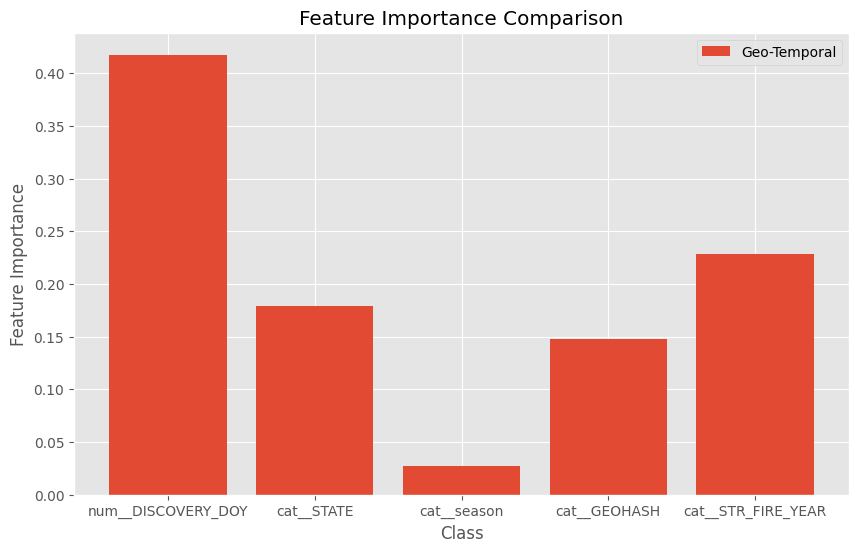

In [ ]:

plt.figure(figsize=(10, 6))
feature_names  = geo_temporal_pipeline.named_steps['preprocessor'].get_feature_names_out()
plt.bar( feature_names,geo_temporal_pipeline.named_steps['classifier'].feature_importances_, label='Geo-Temporal')

plt.xlabel('Class')
plt.ylabel('Feature Importance')
plt.title('Feature Importance Comparison')
plt.legend()
plt.show()

In [ ]:
print(feature_names,geo_temporal_pipeline.named_steps['classifier'].feature_importances_)

['num__DISCOVERY_DOY' 'cat__STATE' 'cat__season' 'cat__GEOHASH'
 'cat__STR_FIRE_YEAR'] [0.41757295 0.17895898 0.02704779 0.14822406 0.22819622]


## is arson prediction

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Perceptron
from sklearn.metrics import classification_report, f1_score


df['is_arson'] = (df['STAT_CAUSE_DESCR'] == 'Arson')


X = df[['STATE', 'LATITUDE', 'LONGITUDE','season', 'DAY_OF_WEEK', 'GEOHASH','log_fire_size', 'OWNER_DESCR','DISCOVERY_DOY' ]]
y = df['is_arson']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


numerical_features = ['LATITUDE', 'LONGITUDE', 'log_fire_size','DISCOVERY_DOY']
categorical_features = ['STATE', 'season', 'DAY_OF_WEEK',  'OWNER_DESCR']


preprocessor_no_scale = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_features),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), ["GEOHASH"]),

        ('oneHot', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),

    ],
    remainder='passthrough'
)



In [ ]:

print("\n--- Training Perceptron model WITHOUT feature scaling ---")
perceptron_no_scale_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_no_scale),
    ('classifier', Perceptron(random_state=42, tol=1e-3))
])
perceptron_no_scale_pipeline.fit(X_train, y_train)
preds_no_scale = perceptron_no_scale_pipeline.predict(X_test)
report_no_scale = classification_report(y_test, preds_no_scale, output_dict=True)

In [ ]:
report_no_scale

{'False': {'precision': 0.9151004131304101,
  'recall': 0.7778219023020494,
  'f1-score': 0.8408952231888566,
  'support': 319802.0},
 'True': {'precision': 0.3185410392649569,
  'recall': 0.5900232719262404,
  'f1-score': 0.41372222948859283,
  'support': 56291.0},
 'accuracy': 0.7497135017136719,
 'macro avg': {'precision': 0.6168207261976835,
  'recall': 0.6839225871141449,
  'f1-score': 0.6273087263387247,
  'support': 376093.0},
 'weighted avg': {'precision': 0.8258115305554613,
  'recall': 0.7497135017136719,
  'f1-score': 0.7769589228897775,
  'support': 376093.0}}

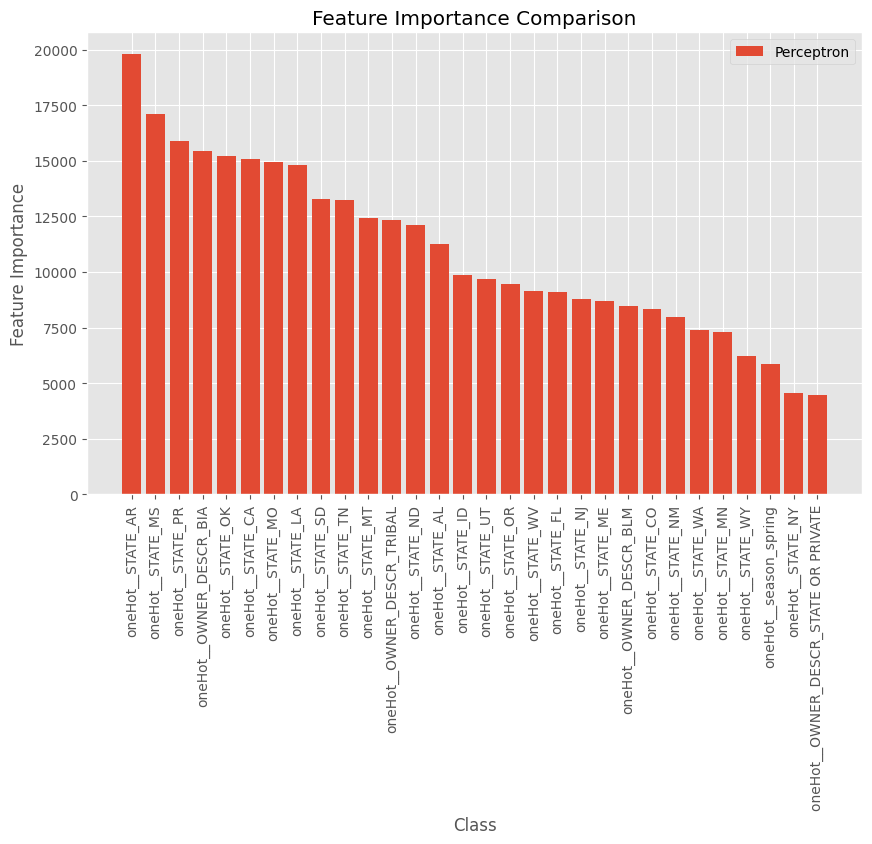

In [ ]:

plt.figure(figsize=(10, 6))
feature_names  = perceptron_no_scale_pipeline.named_steps['preprocessor'].get_feature_names_out()

feature_importanc = zip(perceptron_no_scale_pipeline.named_steps['classifier'].coef_[0], feature_names)
feature_importanc = sorted(feature_importanc, key=lambda x: abs(x[0]), reverse=True)
feature_importanc = feature_importanc[:30]
feature_names = [x[1] for x in feature_importanc]
feature_importanc = [abs(x[0]) for x in feature_importanc]
plt.bar( feature_names,feature_importanc, label='Perceptron')

plt.xticks(rotation=90)
plt.xlabel('Class')
plt.ylabel('Feature Importance')
plt.title('Feature Importance Comparison')
plt.legend()
plt.show()

In [ ]:

# from sklearn.decomposition import PCA
# svm_pipeline = Pipeline(steps=[
#     ('preprocessor', preprocessor_no_scale),
#     ('pca', PCA(n_components=0.95)),
#     ('classifier', SVC(random_state=42))
# ])
# svm_pipeline.fit(X_train, y_train)
# preds_svm = svm_pipeline.predict(X_test)
# report_svm = classification_report(y_test, preds_svm, output_dict=True)
# f1_svm = report_svm['1']['f1-score']
# print(f"F1-score for 'Arson' (SVM): {f1_svm:.2f}")
# report_svm

## pattern clustering

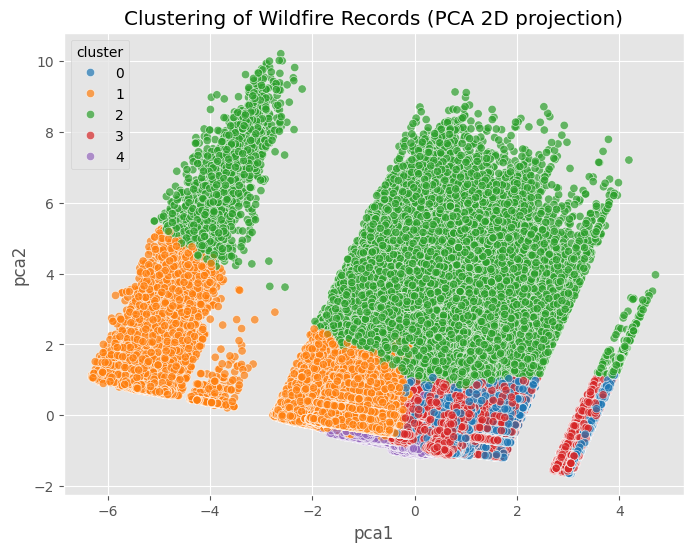

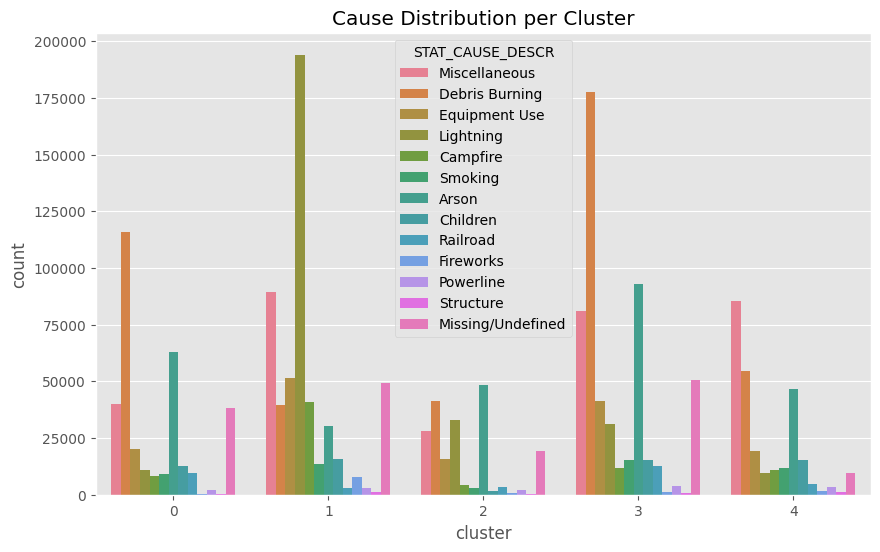

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer



features = ['LATITUDE', 'LONGITUDE', 'season', 'DAY_OF_WEEK', 'log_fire_size']
categorical_features = ['season', 'DAY_OF_WEEK']
numerical_features = ['LATITUDE', 'LONGITUDE', 'log_fire_size']


preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)


pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('cluster', KMeans(n_clusters=5, random_state=42))
])

df['cluster'] = pipeline.fit_predict(df[features])


pca = PCA(n_components=2)
X_transformed = pca.fit_transform(preprocessor.fit_transform(df[features]))
df['pca1'] = X_transformed[:, 0]
df['pca2'] = X_transformed[:, 1]


plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='pca1', y='pca2', hue='cluster', palette='tab10', alpha=0.7)
plt.title("Clustering of Wildfire Records (PCA 2D projection)")
plt.show()


plt.figure(figsize=(10,6))
sns.countplot(data=df, x='cluster', hue='STAT_CAUSE_DESCR', order=sorted(df['cluster'].unique()))
plt.title("Cause Distribution per Cluster")
plt.show()




In [ ]:
print("\n--- Cluster counts ---")
print(df['cluster'].value_counts())

print("\n--- Cause distribution per cluster ---")
print(pd.crosstab(df['cluster'], df['STAT_CAUSE_DESCR'], normalize='index').round(2))

print("\n--- Season distribution per cluster ---")
print(pd.crosstab(df['cluster'], df['season'], normalize='index').round(2))

print("\n--- Day of week distribution per cluster ---")
print(pd.crosstab(df['cluster'], df['DAY_OF_WEEK'], normalize='index').round(2))


print("\n--- Cluster location stats ---")
print(df.groupby('cluster')[['LATITUDE', 'LONGITUDE']].agg(['mean', 'std', 'min', 'max']).round(3))


print("\n--- Rare causes per cluster ---")
rare_causes = df.groupby('cluster')['STAT_CAUSE_DESCR'].value_counts(normalize=True).loc[lambda x: x < 0.1]
print(rare_causes)


--- Cluster counts ---
cluster
1    539788
3    535493
0    330234
4    273858
2    201092
Name: count, dtype: int64

--- Cause distribution per cluster ---
STAT_CAUSE_DESCR  Arson  Campfire  Children  Debris Burning  Equipment Use  \
cluster                                                                      
0                  0.19      0.02      0.04            0.35           0.06   
1                  0.06      0.08      0.03            0.07           0.09   
2                  0.24      0.02      0.01            0.21           0.08   
3                  0.17      0.02      0.03            0.33           0.08   
4                  0.17      0.04      0.06            0.20           0.07   

STAT_CAUSE_DESCR  Fireworks  Lightning  Miscellaneous  Missing/Undefined  \
cluster                                                                    
0                      0.00       0.03           0.12               0.12   
1                      0.01       0.36           0.17              

LATITUDE              0
LONGITUDE             0
season                0
DAY_OF_WEEK           0
log_fire_size         0
DURATION_DAY     891531
DISCOVERY_DOY         0
dtype: int64


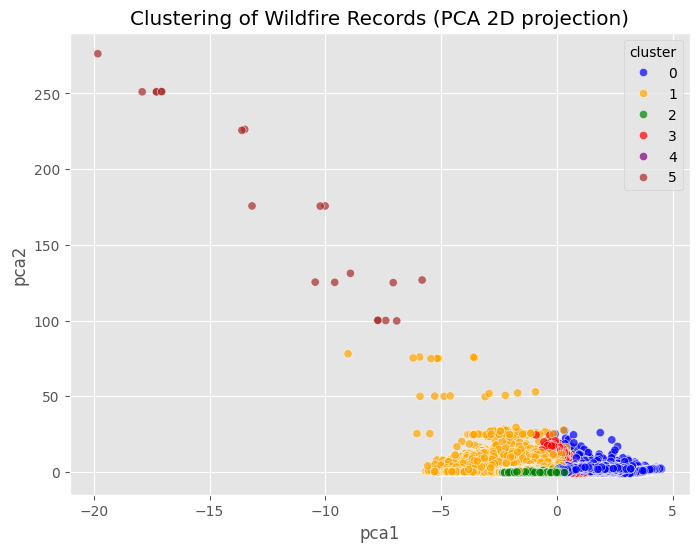

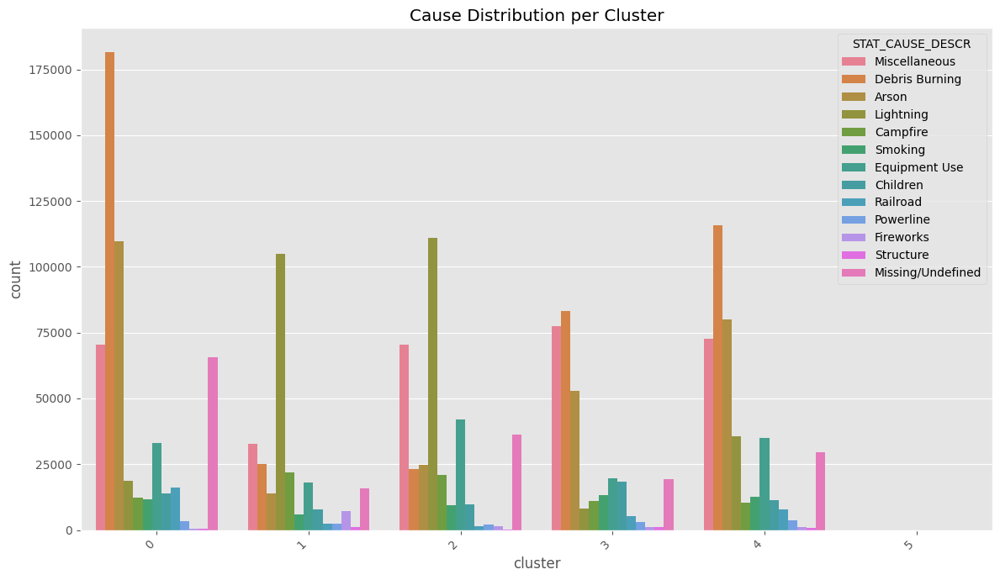


--- ניתוח גודל השריפה ומשכה פר אשכול ---
         log_fire_size  DURATION_DAY
cluster                             
0             1.702448      0.396485
1             1.145635      3.259503
2             0.401765      0.647175
3             0.547739      1.195401
4             1.197988      0.308223
5             0.720361   2578.100000


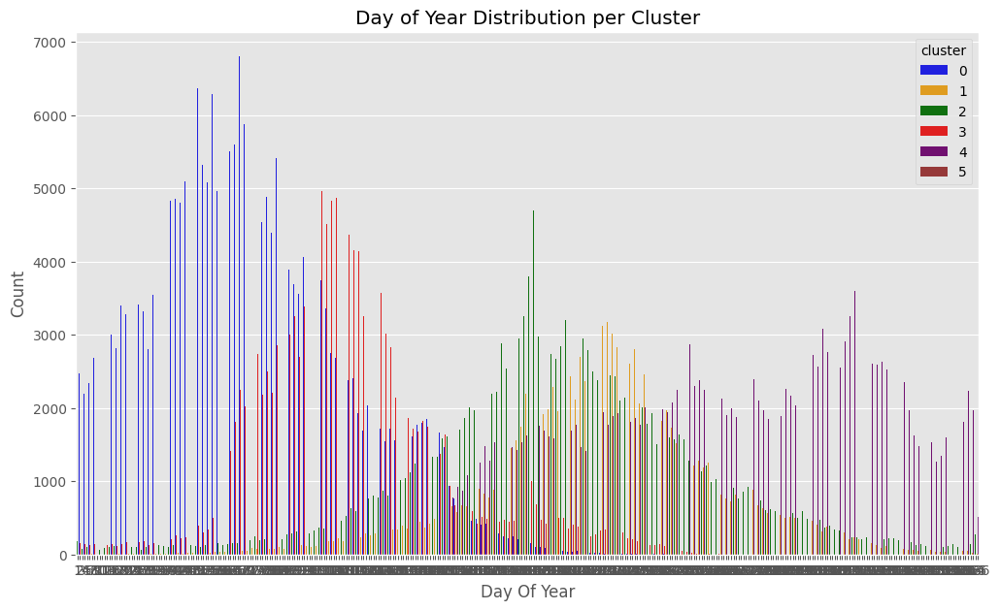

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
import folium
from sklearn.impute import SimpleImputer




features = ['LATITUDE', 'LONGITUDE', 'season', 'DAY_OF_WEEK', 'log_fire_size', 'DURATION_DAY', 'DISCOVERY_DOY']
categorical_features = ['season', 'DAY_OF_WEEK']
numerical_features = ['LATITUDE', 'LONGITUDE', 'log_fire_size', 'DURATION_DAY', 'DISCOVERY_DOY']
print(df[features].isna().sum())

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),


    ],

    remainder='drop'
)


pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('cluster', KMeans(n_clusters=6, random_state=42))
])

df['cluster'] = pipeline.fit_predict(df[features])


pca = PCA(n_components=2)

X_transformed = pca.fit_transform(preprocessor.fit_transform(df[features]))
df['pca1'] = X_transformed[:, 0]
df['pca2'] = X_transformed[:, 1]
colors =colors = {0: 'blue', 1: 'orange', 2: 'green', 3: 'red', 4: 'purple', 5: 'brown'}


plt.figure(figsize=(8,6))

sns.scatterplot(data=df, x='pca1', y='pca2', hue='cluster', palette=colors, alpha=0.7)
plt.title("Clustering of Wildfire Records (PCA 2D projection)")
plt.show()


plt.figure(figsize=(12,7))

sns.countplot(data=df, x='cluster', hue='STAT_CAUSE_DESCR', order=sorted(df['cluster'].unique()))
plt.title("Cause Distribution per Cluster")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


print("\n--- ניתוח גודל השריפה ומשכה פר אשכול ---")
cluster_summary = df.groupby('cluster')[['log_fire_size', 'DURATION_DAY']].mean()
print(cluster_summary)

plt.figure(figsize=(12,7))

sns.countplot(data=df, x='DISCOVERY_DOY', hue='cluster', palette=colors)
plt.title("Day of Year Distribution per Cluster")
plt.xlabel("Day Of Year")
plt.ylabel("Count")
plt.show()

In [ ]:
print("\n--- Cluster counts ---")
print(df['cluster'].value_counts())

print("\n--- Cause distribution per cluster ---")
print(pd.crosstab(df['cluster'], df['STAT_CAUSE_DESCR'], normalize='index').round(2))

print("\n--- Season distribution per cluster ---")
print(pd.crosstab(df['cluster'], df['season'], normalize='index').round(2))

print("\n--- Day of week distribution per cluster ---")
print(pd.crosstab(df['cluster'], df['DAY_OF_WEEK'], normalize='index').round(2))


print("\n--- Cluster location stats ---")
print(df.groupby('cluster')[['LATITUDE', 'LONGITUDE']].agg(['mean', 'std', 'min', 'max']).round(3))


print("\n--- Rare causes per cluster ---")
rare_causes = df.groupby('cluster')['STAT_CAUSE_DESCR'].value_counts(normalize=True).loc[lambda x: x < 0.1]
print(rare_causes)


--- Cluster counts ---
cluster
0    537643
4    416417
2    352867
3    313879
1    259639
5        20
Name: count, dtype: int64

--- Cause distribution per cluster ---
STAT_CAUSE_DESCR  Arson  Campfire  Children  Debris Burning  Equipment Use  \
cluster                                                                      
0                  0.20      0.02      0.03            0.34           0.06   
1                  0.05      0.08      0.03            0.10           0.07   
2                  0.07      0.06      0.03            0.07           0.12   
3                  0.17      0.03      0.06            0.27           0.06   
4                  0.19      0.02      0.03            0.28           0.08   
5                  0.10      0.10      0.00            0.30           0.05   

STAT_CAUSE_DESCR  Fireworks  Lightning  Miscellaneous  Missing/Undefined  \
cluster                                                                    
0                      0.00       0.03           0.13

In [ ]:

sample_df = df.sample(n=10000, random_state=42)
fire_map = folium.Map(location=[39.8283, -98.5795], zoom_start=4)

colors = {0: 'blue', 1: 'orange', 2: 'green', 3: 'red', 4: 'purple'}

for index, row in sample_df.iterrows():
    folium.CircleMarker(
        location=[row['LATITUDE'], row['LONGITUDE']],
        radius=3,
        color=colors[row['cluster']],
        fill=True,
        fill_color=colors[row['cluster']],
        fill_opacity=0.7
    ).add_to(fire_map)

print("\n--- מפה אינטראקטיבית של האשכולות ---")


--- מפה אינטראקטיבית של האשכולות ---


In [ ]:
from folium.plugins import Legend


legend_html = """
     <div style="position: fixed;
                 bottom: 50px; left: 50px; width: 150px; height: 110px;
                 border:2px solid grey; z-index:9999; font-size:14px;
                 background-color:white; opacity:0.9;">
                 &nbsp; <b>Wildfire Cluster Legend</b> <br>
                 &nbsp; <i style="background:blue; border:2px solid grey;"></i> Cluster 0 <br>
                 &nbsp; <i style="background:orange; border:2px solid grey;"></i> Cluster 1 <br>
                 &nbsp; <i style="background:green; border:2px solid grey;"></i> Cluster 2 <br>
                 &nbsp; <i style="background:red; border:2px solid grey;"></i> Cluster 3 <br>
                 &nbsp; <i style="background:purple; border:2px solid grey;"></i> Cluster 4 <br>
                 &nbsp; <i style="background:brown; border:2px solid grey;"></i> Cluster 5 <br>
     </div>
     """

fire_map.get_root().html.add_child(folium.Element(legend_html))

In [ ]:
fire_map